# Exercise 4 — Supernovae in their hosts

*Covers notebooks 07–08. Difficulty: ★★★☆☆*

SNe Ia are observed on top of their host galaxy. How much does the host degrade the
observation, and can it be observed itself? SNR per resolution element, rest-frame 4000–7000 Å,
unless stated otherwise. In the narrow field, a spaxel is 0.04 arcsec.

In [1]:
### use pre-cached data, just in case SVO and STScI archive servers are down for sncosmo downloads during experimentation
### for JupyterAI experimentation, feel free to uncomment this -- any newly downloaded data will go to ~/.cache/astropy/sncosmo/ and other places
import os, shutil
MOUNT = os.path.expanduser('~/s3/schmidt-observatory-system')
SRC = f'{MOUNT}/nov26-symposium/sncosmo_data_dir'
DEST = '/home/jovyan/sncosmo_data_dir'

# Copy only if it isn't already there (skip re-copying on every run)
if not os.path.exists(DEST):
    shutil.copytree(SRC, DEST)

# set sncosmo's environment variable for its default data directory
os.environ['SNCOSMO_DATA_DIR'] = DEST

import numpy as np
import matplotlib.pyplot as plt
import slicersim
from astropy.cosmology import Planck18

snr_range = dict(lbda_range=[4000, 7000], frame="rest")

### 4.1 — Does the host matter?

A SN Ia at $z=1$ in NGC 0628 (`host="ngc0628"`, the host centered in the field). With a fixed
readout `nmd=(47, 8, 0)`, `nramps=1`, compute the SNR and the host share of the variance for:
no host, the SN on the host core, and the SN 0.2", 0.5" and 1" away from the core.

*Hint: move the SN with `pointsource__position`;
`target.simulation.get_band_variance_contribution(**snr_range)["frac_host"]` gives the host
share of the variance.*

In [2]:
def observe(host, offset_arcsec=0, redshift=1.0):
    target = slicersim.LazuliSupernova(redshift=redshift, host=host)
    target.change_properties(pointsource__position=(offset_arcsec / 0.04, 0))
    target.change_detector(nmd=(47, 8, 0), nramps=1)
    snr = target.get_band_snr(**snr_range)
    frac_host = target.simulation.get_band_variance_contribution(**snr_range)["frac_host"]
    return snr, frac_host

snr_nohost, _ = observe(None)
print(f"no host        : SNR={snr_nohost:.2f}")
for offset in [0, 0.2, 0.5, 1]:
    snr, frac_host = observe("ngc0628", offset)
    print(f"{offset:3.1f}\" from core: SNR={snr:.2f} ({snr / snr_nohost:.0%} of no host), host share {frac_host:.1%}")
# For a typical galaxy (M_r=-21), the host costs at most ~4% of the SNR, even on the core, and
# nothing beyond ~0.5": its share of the variance is a few percent. The Lazuli PSF is small, so
# little host light falls under the SN; the detector and the SN itself dominate the noise.

no host        : SNR=9.89


0.0" from core: SNR=9.51 (96% of no host), host share 7.7%


0.2" from core: SNR=9.78 (99% of no host), host share 2.3%


0.5" from core: SNR=9.85 (100% of no host), host share 1.0%


1.0" from core: SNR=9.89 (100% of no host), host share 0.1%


### 4.2 — Brighter, more compact hosts

Keep the SN on the host core. Vary the host absolute magnitude `magabs` from −20 to −24 for:

- (a) NGC 0628,
- (b) a compact, bulge-like host: `{"refmodel": "sersic:bb-5000", "r_kpc": 1, "n": 4, "position": (0, 0)}`.

Plot the SNR relative to the no-host case against `magabs`. When does the host become the
dominant source of variance (host share > 50%)?

*Hint: give the host as a dict to set its parameters, or change them with
`change_properties(host__magabs=...)`.*

     NGC 0628: host share > 50% for magabs <= -24.0


compact bulge: host share > 50% for magabs <= -22.0


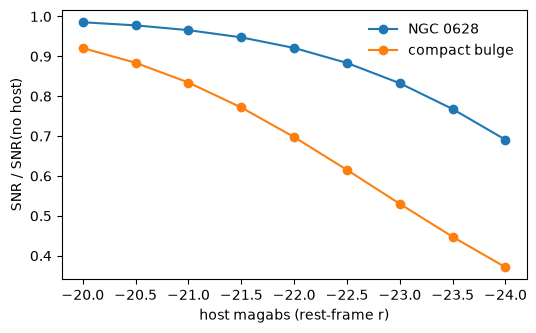

In [3]:
magabs = np.arange(-20, -24.5, -0.5)
hosts = {"NGC 0628": {"refmodel": "ngc0628"},
         "compact bulge": {"refmodel": "sersic:bb-5000", "r_kpc": 1, "n": 4, "position": (0, 0)}}

fig, ax = plt.subplots(figsize=(6, 3.5))
for name, host in hosts.items():
    target = slicersim.LazuliSupernova(redshift=1.0, host=host)
    target.change_detector(nmd=(47, 8, 0), nramps=1)
    snrs, fracs = [], []
    for mag in magabs:
        target.change_properties(host__magabs=mag)
        snrs.append(target.get_band_snr(**snr_range))
        fracs.append(target.simulation.get_band_variance_contribution(**snr_range)["frac_host"])
    ax.plot(magabs, np.asarray(snrs) / snr_nohost, "o-", label=name)
    dominant = magabs[np.asarray(fracs) > 0.5]
    print(f"{name:>13s}: host share > 50% for magabs <= {dominant.max() if len(dominant) else 'never'}")

ax.set(xlabel="host magabs (rest-frame r)", ylabel="SNR / SNR(no host)", xlim=(-19.8, -24.2))
ax.legend(frameon=False)
# NGC 0628 only dominates the noise for magabs <= -24 (a very bright galaxy), while the compact
# bulge does so from magabs <= -22, and degrades the SNR much faster: what matters is the host
# surface brightness under the SN, i.e. how concentrated the light is, not only the total flux.

### 4.3 — Host contamination and redshift

A SN at 3 kpc (projected) from the core of NGC 0628. For $z$ = 0.3, 0.6, 1.0 and 1.5, measure
the host flux under the SN relative to the SN flux, within a 0.1" aperture centered on the SN.
How does the contamination change with redshift, and why?

*Hint: 3 kpc is `3 * Planck18.arcsec_per_kpc_proper(z).value` arcsec. Use
`get_spectrum(method="aperture", incl_error=False)` for the SN and
`get_spectrum(of_host=True, method="aperture", incl_error=False)` for the host, with
`aperture="0.1-arcsec"` and `aperture__position` set to the SN position.*

In [4]:
redshifts = [0.3, 0.6, 1.0, 1.5]
contamination = []
for z in redshifts:
    offset = 3 * Planck18.arcsec_per_kpc_proper(z).value / 0.04   # [spaxels]
    target = slicersim.LazuliSupernova(redshift=z, host="ngc0628")
    target.change_properties(pointsource__position=(offset, 0),
                             aperture="0.1-arcsec", aperture__position=(offset, 0))
    lbda, flux_sn, _ = target.get_spectrum(method="aperture", incl_error=False)
    _, flux_host, _ = target.get_spectrum(of_host=True, method="aperture", incl_error=False)
    restframe = (lbda > 4000 * (1 + z)) & (lbda < 7000 * (1 + z))
    contamination.append(flux_host[restframe].sum() / flux_sn[restframe].sum())
    print(f"z={z}: SN at {offset * 0.04:.2f}\", host/SN within 0.1\" = {contamination[-1]:.1%}")

# area covered by the 0.1" aperture, in kpc^2
area = [np.pi * (0.1 / Planck18.arcsec_per_kpc_proper(z).value) ** 2 for z in redshifts]
print("aperture area [kpc²]:", np.round(area, 2))
# The contamination increases with redshift. The SN and its host are dimmed the same way, but a
# fixed angular aperture (0.1") covers a larger physical area at higher redshift (0.7 -> 2.4 kpc²):
# it collects more host light for the same SN light. The ratio follows the area (x3.6 vs x3.4).

z=0.3: SN at 0.65", host/SN within 0.1" = 1.8%


z=0.6: SN at 0.44", host/SN within 0.1" = 4.1%


z=1.0: SN at 0.36", host/SN within 0.1" = 5.5%


z=1.5: SN at 0.35", host/SN within 0.1" = 6.1%
aperture area [kpc²]: [0.66 1.49 2.13 2.37]


### 4.4 — Which extraction?

The SN at $z=1$ sits on the core of a bright compact host (the compact bulge of 4.2, with
`magabs=-22`). Find the exposure time needed to reach SNR=10 with the optimal extraction, and with
aperture photometry within 0.1" and 0.2". Which one would you use?

*Hint: store the extraction with `change_properties(method=..., aperture=...)`, then
`setup_to_snr()`.*

In [5]:
target = slicersim.LazuliSupernova(redshift=1.0, host=hosts["compact bulge"] | {"magabs": -22})
for method, aperture in [("optimal", "1-arcsec"), ("aperture", "0.1-arcsec"), ("aperture", "0.2-arcsec")]:
    target.change_properties(method=method, aperture=aperture)
    config, snr = target.setup_to_snr(10, **snr_range)
    label = method if method == "optimal" else f"aperture {aperture}"
    frac_host = target.simulation.get_band_variance_contribution(**snr_range)["frac_host"]
    print(f"{label:>20s}: {config}, SNR={snr:.1f}, {target.get_exposure_time() / 60:.0f} min, host share {frac_host:.0%}")
# The optimal extraction is the fastest: it weights the spaxels by the PSF, i.e. where the SN
# dominates over the host. A plain aperture adds the host (and sky) noise of all its spaxels; the
# larger it is, the worse. Aperture photometry is only useful if the PSF is poorly known.

             optimal: {'nmd': [54, 8, 0], 'nramps': 2}, SNR=10.6, 41 min, host share 53%


 aperture 0.1-arcsec: {'nmd': (64, 8, 0), 'nramps': 2}, SNR=9.4, 48 min, host share 55%


 aperture 0.2-arcsec: {'nmd': (64, 8, 0), 'nramps': 5}, SNR=10.3, 121 min, host share 42%


### 4.5 — Observing the host itself

Without the SN (`LazuliGalaxy`), what exposure time is needed to reach SNR=5 on the galaxy
spectrum within 2 kpc of its center, for NGC 0628 and for `"sersic:bb-5000"`, at $z$ = 0.3,
0.6 and 1.0? With the same readout, what SNR does a fixed 1" aperture give? Which aperture
would you use to compare hosts at different redshifts?

*Hint: `slicersim.LazuliGalaxy(redshift, model=..., aperture="2-kpc")`; the aperture can then be
changed with `change_properties(aperture=...)`, without changing the readout.*

In [6]:
for model in ["ngc0628", "sersic:bb-5000"]:
    for z in [0.3, 0.6, 1.0]:
        galaxy = slicersim.LazuliGalaxy(redshift=z, model=model, aperture="2-kpc")
        config, snr_kpc = galaxy.setup_to_snr(5, **snr_range)
        galaxy.change_properties(aperture="1-arcsec")          # same readout
        snr_arcsec = galaxy.get_band_snr(**snr_range)
        radius = 2 * Planck18.arcsec_per_kpc_proper(z).value
        print(f"{model:>15s} z={z}: {galaxy.get_exposure_time() / 60:5.1f} min, "
              f"SNR within 2 kpc ({radius:.2f}\"): {snr_kpc:.1f}, within 1\": {snr_arcsec:.1f}")
# For the extended NGC 0628, the 1" aperture collects more galaxy light and gives a higher SNR;
# for the more concentrated Sersic profile, the outer spaxels mostly add noise and the 2 kpc
# aperture is better at high redshift. To compare hosts at different redshifts, use a kpc
# aperture: it samples the same physical region (e.g. the core) whatever the redshift, while a
# 1" aperture has a radius of 4.6 kpc at z=0.3 but 8.2 kpc at z=1.

        ngc0628 z=0.3:   9.4 min, SNR within 2 kpc (0.44"): 5.7, within 1": 6.4


        ngc0628 z=0.6:  12.1 min, SNR within 2 kpc (0.29"): 4.4, within 1": 4.8


        ngc0628 z=1.0:  23.8 min, SNR within 2 kpc (0.24"): 4.4, within 1": 4.5


 sersic:bb-5000 z=0.3:   6.8 min, SNR within 2 kpc (0.44"): 4.3, within 1": 4.0


 sersic:bb-5000 z=0.6:  12.1 min, SNR within 2 kpc (0.29"): 5.0, within 1": 4.2


 sersic:bb-5000 z=1.0:  23.8 min, SNR within 2 kpc (0.24"): 5.0, within 1": 3.8
